# CI/CD from Zero to a Production-Style Pipeline
### Interactive Jupyter tutorial | Python · pytest · FastAPI · Docker · GitHub Actions

**Goal:** Understand CI/CD, build a small API, test it locally, automate the tests on GitHub, package it with Docker, and learn safe deployment practices.

**How to use:** Execute Python cells in order. Terminal commands are **shown as text** unless explicitly identified as notebook-executable. GitHub Actions YAML runs on GitHub, **not inside Jupyter**.

**Requirements:** Python 3.10+, Jupyter. Later chapters need Git, Docker Desktop, and a GitHub repository. Python dependencies are optional for the conceptual lessons.

**Suggested study plan:** 2–3 sessions for CI; 1–2 for Docker/CD; then exercises.

## 0. Learning objectives

By the end you should be able to:

1. Distinguish **CI**, **Continuous Delivery**, and **Continuous Deployment**.
2. Explain push, pull request, workflow, job, step, runner, artifact, registry and environment.
3. Write and run unit tests using `pytest`.
4. Develop and containerize a minimal FastAPI service.
5. Create a GitHub Actions CI workflow and diagnose failures.
6. Publish a container image through a gated CD workflow.
7. Handle secrets, permissions, immutable image tags, smoke tests and rollback responsibly.

> **Golden rule:** A successful build does not prove application correctness, and a successful test suite does not prove production safety.

## 1. What is CI/CD?

**Continuous Integration (CI):** Developers merge small changes frequently. Automated checks on pushes and pull requests detect problems early: static checks, unit tests, and builds.

**Continuous Delivery:** The code is always kept **ready for release**. Packaging and checks are automated, but production deployment can require an explicit approval or manual trigger.

**Continuous Deployment:** Every change that passes required gates is **automatically deployed** to production. This requires confidence in tests, observability, and rollback.

| Concept | Primary question | Typical output |
|---|---|---|
| CI | Is this change safe enough to integrate? | Passing test/build status |
| Continuous Delivery | Could we release this version? | Versioned, validated deployable artifact |
| Continuous Deployment | Has the approved version been released automatically? | Running new production version |

The abbreviation **CD** is ambiguous: people use it for *Delivery* or *Deployment*. Always clarify which.

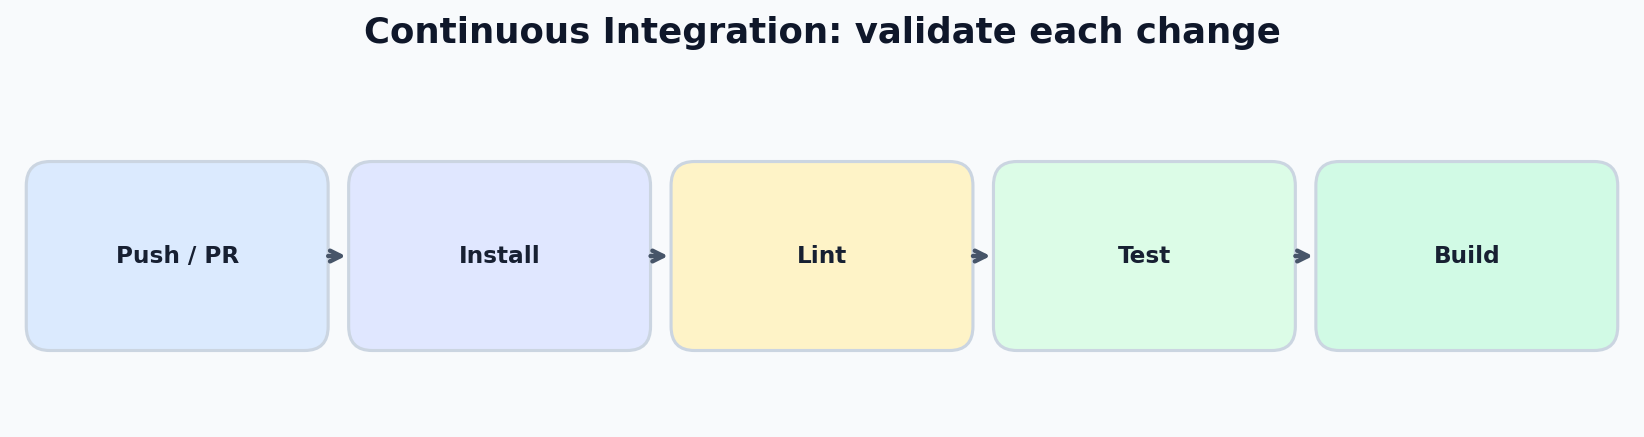

### Example: a chatbot repository

Suppose you change the `/chat` endpoint in a FastAPI chatbot. With CI, a push runs automated checks. A regression is found before merging. With delivery, the passing version is packaged as an image and made ready for release. With deployment, the new image is rolled out to a server and smoke-tested.

A GitHub Actions pipeline usually begins with a **repository event**, not a person clicking “run pytest.”

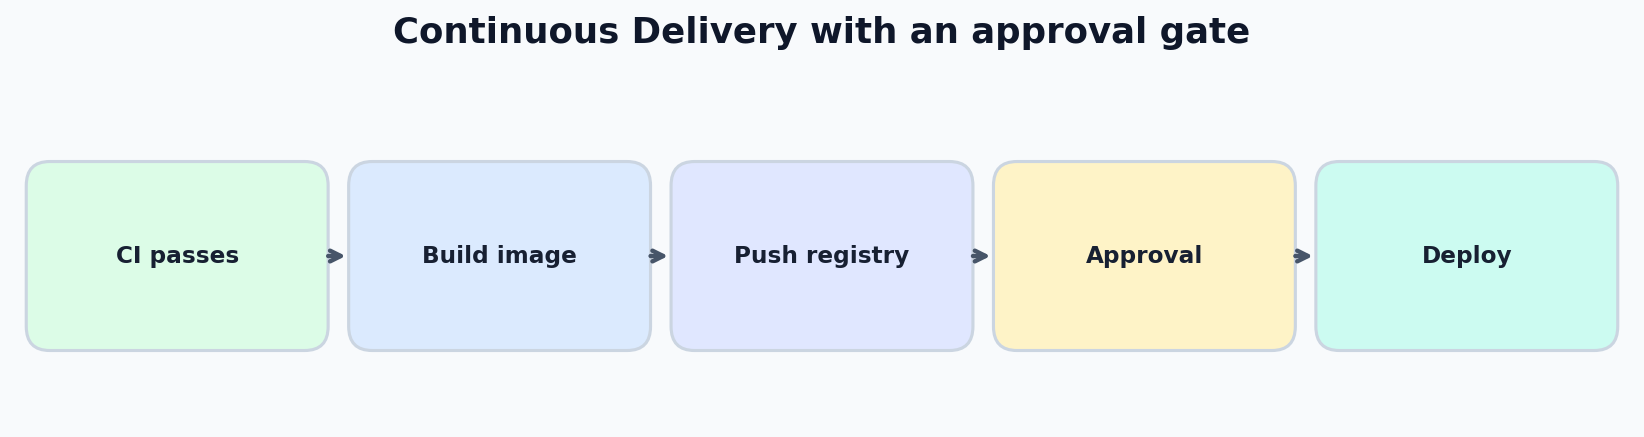

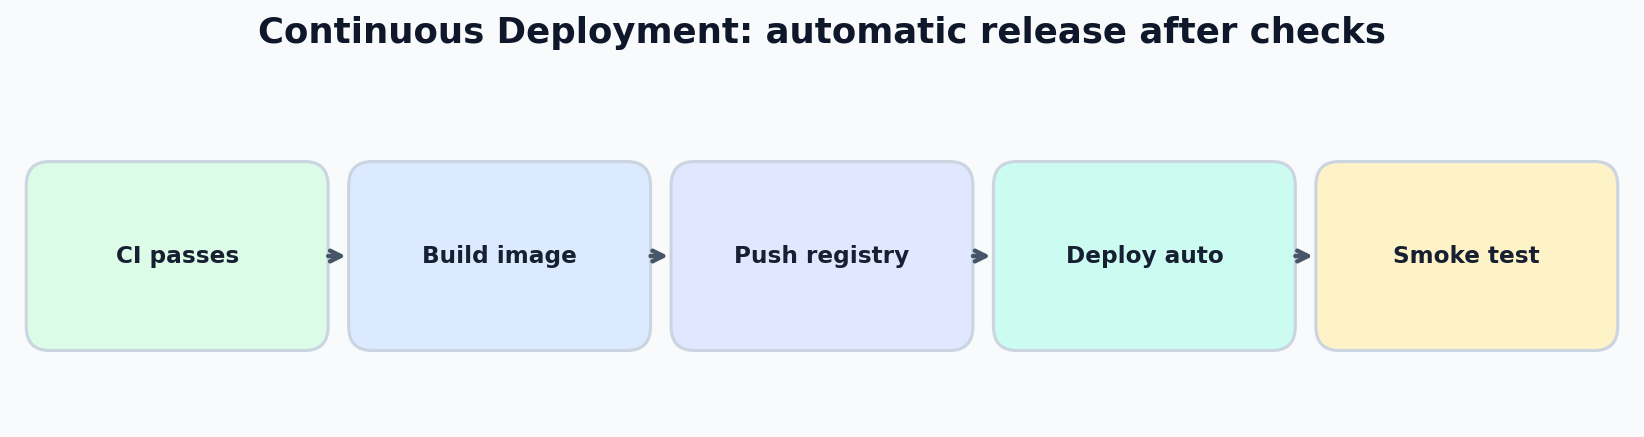

## 2. Understand the vocabulary

- **Repository:** your tracked source code.
- **Commit:** snapshot of changes.
- **Branch:** independent line of work.
- **Pull request (PR):** proposed change that can be reviewed before merge.
- **Workflow:** YAML automation under `.github/workflows/`.
- **Event / trigger:** `push`, `pull_request`, `workflow_dispatch`, or a release.
- **Job:** set of steps run on a runner; jobs can run in parallel.
- **Step:** shell command or reusable action.
- **Runner:** machine that executes the workflow.
- **Artifact:** output saved from a job, such as test coverage or a compiled build.
- **Container registry:** place to store images, e.g. GitHub Container Registry (`ghcr.io`).
- **Environment:** deployment target such as staging or production, often with approvals and protection rules.

**Important distinction:** a Docker image is an artifact; a Docker container is a running instance of that image.

## 3. Git workflow (terminal commands; run in a terminal, not Jupyter)

```bash
git init
git add .
git commit -m "Add first version"
git switch -c feature/health-check
# Edit files, then:
git add .
git commit -m "Improve health check"
git push -u origin feature/health-check
```

Create a pull request on GitHub. A CI workflow configured for `pull_request` begins checking the proposed changes.

**Common pattern:** require passing CI checks before merging into `main` with GitHub branch protection/rulesets.

## 4. Unit testing in plain Python (fully runnable)

Start with a pure function. This cell does **not** need FastAPI, pytest, or a network connection.

In [ ]:
def calculate_total(price: float, quantity: int, discount: float = 0) -> float:
    if price < 0 or quantity < 0 or not 0 <= discount <= 1:
        raise ValueError("Invalid price, quantity or discount")
    return round(price * quantity * (1 - discount), 2)

assert calculate_total(10, 3) == 30
assert calculate_total(10, 3, 0.2) == 24
print("Two checks passed")

### Demonstrate a regression

We deliberately replace the function with a broken implementation in a different name to avoid damaging the working version. The error is caught and printed, so the notebook can continue.

In [ ]:
def broken_calculate_total(price, quantity, discount=0):
    return round(price + quantity - discount, 2)  # BUG: addition instead of multiplication

try:
    assert broken_calculate_total(10, 3) == 30
except AssertionError:
    print("EXPECTED FAIL: regression detected. Got", broken_calculate_total(10, 3))

## 5. pytest and the testing pyramid

- **Unit tests:** small, deterministic, quick. Mock external dependencies where appropriate.
- **Integration tests:** verify components work together (e.g., API + database).
- **End-to-end (E2E) tests:** check an entire user flow. More expensive and brittle.
- **Smoke tests:** tiny checks after deployment to see whether the basic application is alive.

A clean CI pipeline normally runs quick tests on every PR and expensive tests selectively as needed.

### Create your first pytest project

Run the following Python cell in a **new working directory**. It writes the companion project alongside this notebook (or to the current directory). If you opened the notebook inside a folder containing `app/`, the files will be replaced with the tutorial version.

In [ ]:
from pathlib import Path
project = Path("ci_cd_demo")
(project / "app").mkdir(parents=True, exist_ok=True)
(project / "tests").mkdir(parents=True, exist_ok=True)
(project / ".github" / "workflows").mkdir(parents=True, exist_ok=True)
(project / "app" / "__init__.py").write_text("")
print("Created:", project.resolve())

In [ ]:
(project / "app" / "logic.py").write_text("""def calculate_total(price, quantity, discount=0):
    if price < 0 or quantity < 0 or not 0 <= discount <= 1:
        raise ValueError("Invalid inputs")
    return round(price * quantity * (1 - discount), 2)
""")
(project / "tests" / "test_logic.py").write_text("""import pytest
from app.logic import calculate_total

@pytest.mark.parametrize("price,qty,discount,expected", [
    (10, 3, 0, 30),
    (10, 3, 0.2, 24),
    (5, 0, 0, 0),
])
def test_total(price, qty, discount, expected):
    assert calculate_total(price, qty, discount) == expected

def test_invalid_discount():
    with pytest.raises(ValueError):
        calculate_total(10, 1, 2)
""")
print("Unit tests generated")

In your terminal, run:

```bash
cd ci_cd_demo
python -m pip install -r requirements-dev.txt
python -m pytest -v
```

**Expected:** 4 passing test cases (three parameterized inputs plus an error test).

**Why `python -m pytest`?** It uses pytest from the Python environment you chose rather than an unrelated executable installed elsewhere.

## 6. Create a small FastAPI application

Our API has `/health` and `/total` endpoints. The API itself is optional for the earlier pure Python tests. `FastAPI` and `httpx` are installed with the requirements file below.

In [ ]:
(project / "app" / "main.py").write_text("""from fastapi import FastAPI, HTTPException
from app.logic import calculate_total

app = FastAPI(title="CI/CD Learning API", version="1.0.0")

@app.get("/health")
def health():
    return {"status": "ok"}

@app.get("/total")
def total(price: float, quantity: int, discount: float = 0):
    try:
        return {"total": calculate_total(price, quantity, discount)}
    except ValueError as exc:
        raise HTTPException(status_code=422, detail=str(exc)) from exc
""")
(project / "tests" / "test_api.py").write_text("""from fastapi.testclient import TestClient
from app.main import app

client = TestClient(app)

def test_health():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json() == {"status": "ok"}

def test_total_endpoint():
    response = client.get("/total", params={"price": 10, "quantity": 3})
    assert response.status_code == 200
    assert response.json() == {"total": 30.0}
""")
(project / "requirements.txt").write_text('fastapi>=0.115,<1\nuvicorn>=0.30,<1\n')
(project / "requirements-dev.txt").write_text('-r requirements.txt\npytest>=8,<10\nhttpx>=0.27,<1\nruff>=0.9,<1\n')
print("API, API tests, and dependency files generated")

### Test and run locally

From a terminal in `ci_cd_demo/`:

```bash
python -m pip install -r requirements-dev.txt
python -m pytest -v
python -m uvicorn app.main:app --reload
```

Visit `http://127.0.0.1:8000/docs` for interactive documentation and `http://127.0.0.1:8000/health` for health status. Stop the server using `Ctrl+C`.

The API test uses an in-process **TestClient**; no external API server is needed for pytest.

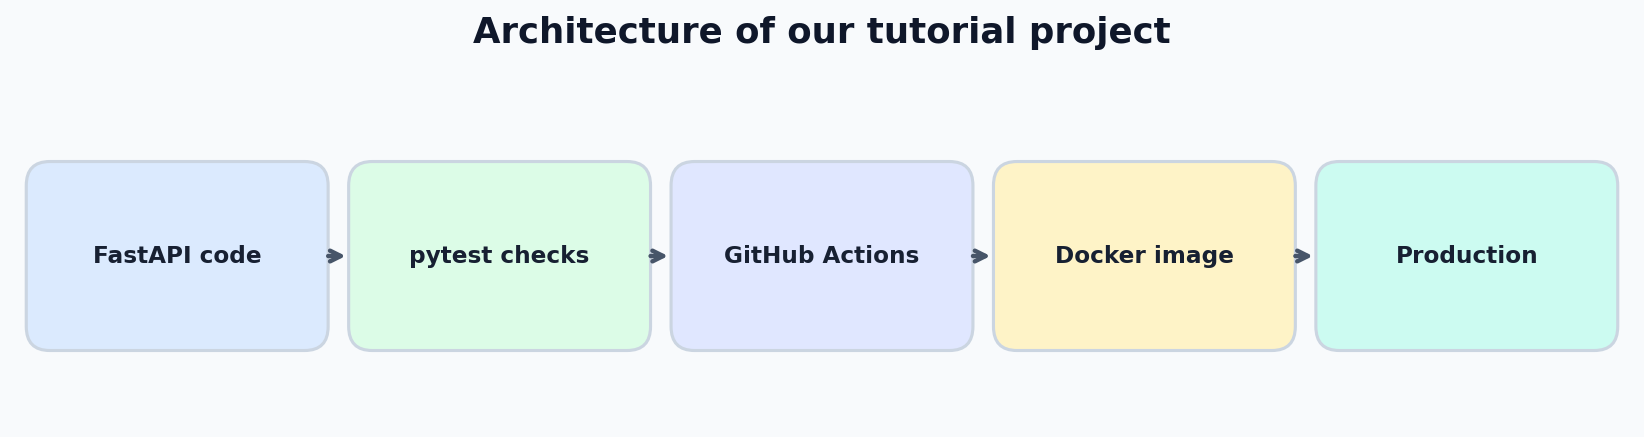

## 7. Linting, formatting, tests, and builds

These checks answer different questions:

| Stage | Tool | Example | Detects |
|---|---|---|---|
| Lint | Ruff | `python -m ruff check .` | Likely bugs/style problems |
| Tests | pytest | `python -m pytest -q` | Behavioral regressions |
| Build | Docker | `docker build -t demo-api:local .` | Packaging problems |
| Smoke | HTTP request | `curl -f localhost:8000/health` | Basic running-service availability |

A green pipeline isn't a substitute for integration tests, observability, review, or security scans.

## 8. First GitHub Actions workflow: CI

GitHub detects YAML files under `.github/workflows/`. This workflow runs on pushes to `main` and pull requests targeting `main`. It installs Python, dependencies, lints, and executes tests.

Read the YAML carefully:

- `on`: events that start the workflow.
- `permissions: contents: read`: grant only repository read access.
- `jobs`: independent work units.
- `runs-on`: runner OS.
- `uses`: invoke reusable action.
- `run`: execute commands.
- `cache: pip`: reuse downloaded Python dependencies.

> **Production note:** For stronger supply-chain security, pin `uses` actions to verified full commit SHAs rather than mutable version tags. Major tags are used here to keep the beginner example readable.

```yaml
name: Python CI

on:
  push:
    branches: [main]
  pull_request:
    branches: [main]

permissions:
  contents: read

jobs:
  checks:
    runs-on: ubuntu-latest
    steps:
      - name: Checkout
        uses: actions/checkout@v6
      - name: Set up Python
        uses: actions/setup-python@v6
        with:
          python-version: '3.12'
          cache: pip
          cache-dependency-path: requirements-dev.txt
      - name: Install dependencies
        run: python -m pip install -r requirements-dev.txt
      - name: Lint
        run: python -m ruff check .
      - name: Test
        run: python -m pytest -v
```

In [ ]:
(project / ".github" / "workflows" / "ci.yml").write_text("name: Python CI\n\non:\n  push:\n    branches: [main]\n  pull_request:\n    branches: [main]\n\npermissions:\n  contents: read\n\njobs:\n  checks:\n    runs-on: ubuntu-latest\n    steps:\n      - name: Checkout\n        uses: actions/checkout@v6\n      - name: Set up Python\n        uses: actions/setup-python@v6\n        with:\n          python-version: '3.12'\n          cache: pip\n          cache-dependency-path: requirements-dev.txt\n      - name: Install dependencies\n        run: python -m pip install -r requirements-dev.txt\n      - name: Lint\n        run: python -m ruff check .\n      - name: Test\n        run: python -m pytest -v\n")
print("Created .github/workflows/ci.yml")

### Trigger CI for real

1. Make a GitHub repository, then upload/push the **contents of `ci_cd_demo/`** to its root.
2. Open the repository's **Actions** tab and inspect `Python CI`.
3. Create a branch, deliberately change `calculate_total` to use addition, push, and open a PR.
4. Inspect the failed test's log. Revert the bug, push again, and check the workflow turns green.
5. Configure a GitHub ruleset/branch protection policy to require the **checks** job before merge.

**Troubleshooting:** If the workflow cannot find files, inspect the repository root and `working-directory`. If setup Python or pip caching fails, check the dependency path and action version.

## 9. Docker fundamentals

- **Dockerfile:** recipe for building an image.
- **Image:** immutable-by-digest package containing application and dependencies.
- **Container:** running instance created from the image.
- **Port mapping:** `-p 8000:8000` publishes the container port on your machine.
- **`.dockerignore`:** keeps secrets, virtual environments and irrelevant files out of the build context.

Docker commands shown here **require Docker Desktop or another Docker engine**. Jupyter cannot run Docker unless the host environment provides it.

```dockerfile
FROM python:3.12-slim
WORKDIR /app
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app ./app
RUN useradd --create-home --uid 10001 appuser
USER appuser
EXPOSE 8000
CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]
```

In [ ]:
(project / "Dockerfile").write_text('FROM python:3.12-slim\nWORKDIR /app\nENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1\nCOPY requirements.txt .\nRUN pip install --no-cache-dir -r requirements.txt\nCOPY app ./app\nRUN useradd --create-home --uid 10001 appuser\nUSER appuser\nEXPOSE 8000\nCMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]\n')
(project / ".dockerignore").write_text('.git\n.github\n.venv\n__pycache__\n.pytest_cache\n.env\n*.pyc\n*.ipynb\n')
print("Created Dockerfile and .dockerignore")

From `ci_cd_demo/` in a terminal:

```bash
docker build -t demo-api:local .
docker run --rm -p 8000:8000 demo-api:local
```

In another terminal:

```bash
curl http://localhost:8000/health
```

Expected response: `{"status":"ok"}`. If port 8000 is occupied, use `-p 8001:8000` and browse port 8001.

**Security reminder:** Never copy `.env` into a public image. Supply secrets at runtime through a secure deployment platform.

## 10. CD: publish a versioned Docker image

A mature workflow separates validation from publishing:

- **CI** runs on PRs and pushes.
- **CD publish** runs after a published GitHub release, re-runs minimum checks, builds and pushes the image to GitHub Container Registry (`ghcr.io`).
- **Deployment** is a separate, controlled step, potentially behind production environment approval.

Using a release trigger prevents every PR from publishing a production image. The workflow below uses a **versioned tag** (the GitHub release tag) rather than overwriting `latest`.

**Prerequisites:** release the code from a trusted branch, grant package write permissions to this workflow, and confirm repository/org package policies. GHCR visibility and access rules are managed separately.

```yaml
name: Publish Docker image
on:
  release:
    types: [published]

permissions:
  contents: read
  packages: write

jobs:
  publish:
    runs-on: ubuntu-latest
    steps:
      - name: Checkout
        uses: actions/checkout@v6
      - name: Set up Python
        uses: actions/setup-python@v6
        with:
          python-version: '3.12'
      - name: Validate
        run: |
          python -m pip install -r requirements-dev.txt
          python -m ruff check .
          python -m pytest -q
      - name: Log in to GHCR
        uses: docker/login-action@v3
        with:
          registry: ghcr.io
          username: ${{ github.actor }}
          password: ${{ secrets.GITHUB_TOKEN }}
      - name: Lowercase image name
        run: echo "IMAGE=ghcr.io/${GITHUB_REPOSITORY,,}" >> "$GITHUB_ENV"
      - name: Build and push
        uses: docker/build-push-action@v6
        with:
          context: .
          push: true
          tags: ${{ env.IMAGE }}:${{ github.event.release.tag_name }}
```

In [ ]:
(project / ".github" / "workflows" / "publish.yml").write_text('name: Publish Docker image\non:\n  release:\n    types: [published]\n\npermissions:\n  contents: read\n  packages: write\n\njobs:\n  publish:\n    runs-on: ubuntu-latest\n    steps:\n      - name: Checkout\n        uses: actions/checkout@v6\n      - name: Set up Python\n        uses: actions/setup-python@v6\n        with:\n          python-version: \'3.12\'\n      - name: Validate\n        run: |\n          python -m pip install -r requirements-dev.txt\n          python -m ruff check .\n          python -m pytest -q\n      - name: Log in to GHCR\n        uses: docker/login-action@v3\n        with:\n          registry: ghcr.io\n          username: ${{ github.actor }}\n          password: ${{ secrets.GITHUB_TOKEN }}\n      - name: Lowercase image name\n        run: echo "IMAGE=ghcr.io/${GITHUB_REPOSITORY,,}" >> "$GITHUB_ENV"\n      - name: Build and push\n        uses: docker/build-push-action@v6\n        with:\n          context: .\n          push: true\n          tags: ${{ env.IMAGE }}:${{ github.event.release.tag_name }}\n')
print("Created publish.yml")

### A critical nuance about releases

The `release` event triggers on the release's selected tag. **Publishing a tag or release is a privileged action.** Protect who can publish releases, and avoid unreviewed changes to workflow files. For stricter production gates, use a protected GitHub Environment, required reviewers, and deploy by a previously verified image **digest**.

**Versioning example:** `ghcr.io/owner/repo:v1.0.0`; an image digest is more precise than a mutable tag.

**Where does production deployment happen?** Not in the publish workflow above. That is intentional: publishing an image is **Continuous Delivery**, not automatic deployment.

## 11. Deploy, monitor, and rollback

A simple deployment pattern for a small API:

1. Pull a tested, immutable image version on the server.
2. Start a new container with configured runtime secrets.
3. Check `/health` and a representative application flow.
4. Monitor request errors, latency and resource usage.
5. If verification fails, redeploy the **previous known-good image digest**.

### Example commands (run on your own server, adapt placeholders)

```bash
# Example only. Replace image reference with your actual registry image.
docker pull ghcr.io/OWNER/REPO:v1.0.0
docker stop demo-api || true
docker rm demo-api || true
docker run -d --restart unless-stopped --name demo-api -p 8000:8000 ghcr.io/OWNER/REPO:v1.0.0
curl --fail http://localhost:8000/health
```

**Warning:** Stopping the old container before verification causes downtime. Use a reverse proxy and blue/green or rolling deployment for availability-sensitive services. Real databases also need safe migrations and backups; container rollback alone does not reverse schema changes.

## 12. Security, quality, and operational best practices

1. **Least privilege:** use `permissions: contents: read` in CI and `packages: write` only for publish jobs.
2. **Never commit credentials:** keep `.env` out of Git, use secret stores and short-lived tokens or OIDC where supported.
3. **Review external actions:** prefer maintained official actions and pin to full commit SHAs for production.
4. **Protect main:** require reviews and passing checks.
5. **Use dependency locks and vulnerability scans:** reproducibility matters more than “worked on my computer.”
6. **Set timeouts:** avoid hanging workflows.
7. **Protect deploy environments:** approvals, restricted branches, dedicated credentials.
8. **Separate staging and production:** do not treat a successful unit test as proof of deploy readiness.
9. **Record deploy versions:** retain image tags and digests.
10. **Watch after deployment:** logs, error budget, latency, alerting and rollback procedure.

For LLM/chatbot services, add **eval datasets** and prompt-injection/unsafe-output regression tests to CI. Avoid calling paid external LLM APIs on every PR unless you intentionally manage cost and reliability.

## 13. Advanced pattern: CI for an AI agent

A traditional test might assert that `/health` returns `200`. An AI service also needs domain-level quality checks:

| Layer | Example check | Expected behavior |
|---|---|---|
| Unit | Prompt builder | Correct system/user message layout |
| Integration | Retriever + test index | Returns an expected reference document |
| API | `/chat` invalid input | Returns 4xx with clear error |
| Evaluation | Fixed dataset of 20 questions | Accuracy and grounding exceed threshold |
| Security | Known prompt injection | Agent does not expose secrets |
| Deployment | `/health` and test chat | Service and model configuration work |

**Do not use nondeterministic LLM outputs as exact text snapshots** unless necessary. Prefer semantic or rubric-based evaluations with clear tolerances. Keep fast deterministic checks separate from slower online evaluations.

## 14. Exercises (do these before looking up solutions)

**Exercise A, CI failure:** Break a calculation and identify the exact failed pytest assertion. Explain why the build should not be published.

**Exercise B, new endpoint:** Add `/version` returning `{"version":"1.0.0"}` and one API test.

**Exercise C, Docker:** Change the host port to `8001` without changing the application source.

**Exercise D, PR workflow:** Explain the behavior of `on: pull_request` vs `on: push`.

**Exercise E, security:** Explain why embedding an API key in `Dockerfile` is unsafe. Propose a better runtime secret strategy.

**Exercise F, delivery vs deployment:** Identify which step actually starts the production container; explain why GHCR publishing is not production deployment.

**Exercise G, release safety:** Describe how to rollback from v1.1.0 to v1.0.0 and one reason the rollback could fail (hint: database migrations).

**Capstone:** Push the generated demo app to GitHub, observe green CI, intentionally fail a PR, correct it, publish a release, and inspect the registry image. Deploy only to a test environment first.

## 15. Knowledge check

1. What makes CI different from simply running tests on your laptop?
2. Is a green CI workflow a guarantee that production deployment is safe?
3. What is the difference between image, container, and registry?
4. Why use PR checks and a protected `main` branch?
5. What is the difference between `packages: write` and `contents: read`?
6. What does an image digest give you that `latest` cannot?

**Answers:**

1. CI runs checks automatically and consistently on repository changes in a shared environment.
2. No. Tests can be incomplete, and deployment introduces infrastructure/data risks.
3. Image = packaged template; container = running instance; registry = image storage/distribution.
4. To reduce the chance of unreviewed or broken code merging.
5. The former allows package publishing, the latter allows repository reading.
6. A stable identifier for exact image content, supporting reproducible deployments and rollback.

## 16. Troubleshooting map

| Error | Likely reason | First check |
|---|---|---|
| `ModuleNotFoundError: fastapi` | Wrong environment | `python -m pip show fastapi` |
| `No module named pytest` | Dev requirements not installed | `python -m pip install -r requirements-dev.txt` |
| `No module named app` | Running from wrong directory | Run from `ci_cd_demo/` root |
| `Docker daemon not running` | Docker engine stopped | Start Docker Desktop |
| `Address already in use` | Port occupied | Map host `8001:8000` |
| GitHub workflow not triggered | Wrong path/event/branch | `.github/workflows/*.yml`, Actions tab |
| GHCR package permission denied | Token or registry policy | `packages: write`, package settings |
| `curl` health check fails | App start/port/network problem | `docker logs demo-api` |

**Important:** Notebook-generated project files appear in the current working directory. Verify it with `Path.cwd()` if you cannot find them.

## 17. Official references and next steps

- [GitHub Docs: Build and test Python](https://docs.github.com/en/actions/tutorials/build-and-test-code/python)
- [GitHub Docs: Publishing Docker images](https://docs.github.com/en/actions/tutorials/publish-packages/publish-docker-images)
- [GitHub Actions: setup-python](https://github.com/actions/setup-python)
- [GitHub Actions: security hardening](https://docs.github.com/en/actions/security-for-github-actions/security-guides/security-hardening-for-github-actions)
- [Docker Docs](https://docs.docker.com/)
- [pytest Docs](https://docs.pytest.org/)

**Recommended path:** Chapters 1–5 locally → run generated project → Chapters 8–10 in GitHub → Chapter 11 in a disposable test environment → finish capstone.

**Scope:** This is an educational project. Before production, add pinned dependencies, comprehensive tests, vulnerability scanning, protected production approvals, real logging/monitoring, and appropriate deployment orchestration.